# EDA preliminar: ¿es `type` una buena variable objetivo?
**Hipótesis a contrastar:** `type` (6 clases) es viable como variable a clasificar.
**Criterios para RECHAZARLA** (los fijamos antes de mirar):
- clases muy desbalanceadas o con muy pocos ejemplos
- está duplicada por otra columna (fuga) o es trivial de predecir
- las variables que quedan disponibles no tienen señal
Se ejecuta por celdas en VS Code / Jupyter / Colab (las líneas `# %%` separan celdas).

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, kruskal
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
RUTA = "dinosaurs.xlsx"          # <- ajusta la ruta
HOJA = "dinosaurs"               # "dinosaurs" = tabla completa (4951 filas) | "Tabla1" = solo filas completas (2793)
TARGET = "type"

df = pd.read_excel(RUTA, sheet_name=HOJA)

## 1. Calidad y estructura de los datos (incluye nulos)

In [11]:
print(df.shape)
df.info()
nulos = df.isna().sum()
print("\nNulos por columna:\n", pd.DataFrame({"n": nulos, "%": (nulos / len(df) * 100).round(1)}))
print("\nFilas duplicadas ignorando el ID:", df.drop(columns="occurrence_no").duplicated().sum())

# Si hay nulos en `type`, esas filas NO tienen etiqueta: no sirven para entrenar un clasificador.
# ¿Los nulos se reparten igual entre grupos o están sesgados?
print("\n% de `type` nulo por class:\n", df.groupby("class")[TARGET].apply(lambda s: s.isna().mean()).round(3))

# Nos quedamos con las filas etiquetadas y con longitud conocida (la variable numérica clave).
antes = len(df)
df = df.dropna(subset=[TARGET, "length_m"]).copy()
print(f"\nFilas usadas: {len(df)} de {antes} (descartadas: {antes - len(df)})")
df.describe().round(2)

(4951, 12)
<class 'pandas.DataFrame'>
RangeIndex: 4951 entries, 0 to 4950
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   occurrence_no  4951 non-null   int64  
 1   name           4951 non-null   str    
 2   diet           3596 non-null   str    
 3   type           3596 non-null   str    
 4   length_m       3568 non-null   float64
 5   max_ma         4951 non-null   float64
 6   min_ma         4951 non-null   float64
 7   region         4909 non-null   str    
 8   lng            4951 non-null   float64
 9   lat            4951 non-null   float64
 10  class          4951 non-null   str    
 11  family         3494 non-null   str    
dtypes: float64(5), int64(1), str(6)
memory usage: 464.3 KB

Nulos por columna:
                   n     %
occurrence_no     0   0.0
name              0   0.0
diet           1355  27.4
type           1355  27.4
length_m       1383  27.9
max_ma            0   0.0
min_ma        

,occurrence_no,length_m,max_ma,min_ma,lng,lat
count,3568.00,3568.00,3568.00,3568.00,3568.00,3568.00
mean,657251.44,8.21,113.08,102.53,-48.75,38.15
std,298664.85,6.63,42.96,42.23,80.05,19.82
min,130209.00,0.45,70.60,66.00,-153.25,-84.33
25%,481935.50,3.00,83.50,66.00,-108.81,38.83
50%,540142.50,6.70,83.60,72.10,-104.61,43.54
75%,786396.25,10.00,155.70,145.00,8.65,48.74
max,1364695.00,35.00,252.17,247.20,177.07,78.10


## 2. Variable objetivo: distribución y desbalanceo

                    n     %
type                       
ornithopod        797  22.3
large theropod    732  20.5
small theropod    717  20.1
sauropod          664  18.6
ceratopsian       355   9.9
armored dinosaur  303   8.5
Ratio clase mayor / menor: 2.63


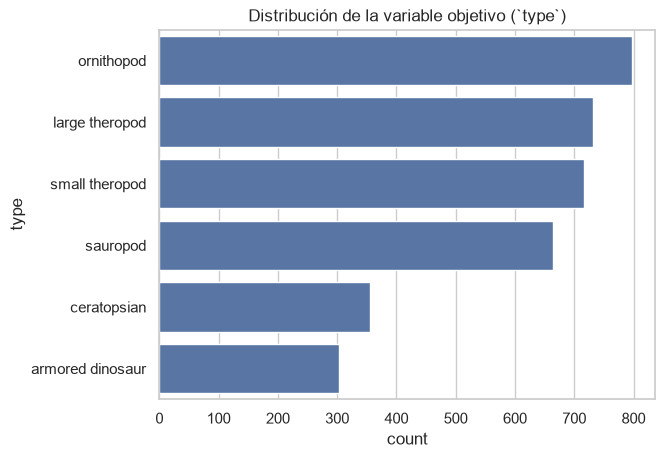

In [12]:
conteo = df[TARGET].value_counts()
print(pd.DataFrame({"n": conteo, "%": (conteo / len(df) * 100).round(1)}))
print("Ratio clase mayor / menor:", round(conteo.max() / conteo.min(), 2))

sns.countplot(data=df, y=TARGET, order=conteo.index)
plt.title("Distribución de la variable objetivo (`type`)")
plt.show()

## 3. Granularidad: ¿filas = dinosaurios o filas = hallazgos fósiles?

In [13]:
print("Filas:", len(df), "| taxones distintos (name):", df["name"].nunique())

# ¿Un mismo name puede tener más de un valor de type/class/diet/family?
por_taxon = df.groupby("name")[[TARGET, "class", "diet", "family"]].nunique()
print("\nMáx. valores distintos por name:\n", por_taxon.max())

# Tamaño real de cada clase si contamos taxones y no hallazgos
comparativa = pd.DataFrame({
    "filas": df[TARGET].value_counts(),
    "taxones": df.groupby(TARGET)["name"].nunique(),
})
print("\n", comparativa)

Filas: 3568 | taxones distintos (name): 288

Máx. valores distintos por name:
 type      1
class     1
diet      1
family    1
dtype: int64

                   filas  taxones
type                            
armored dinosaur    303       28
ceratopsian         355       23
large theropod      732       59
ornithopod          797       54
sauropod            664       68
small theropod      717       56


## 4. Relación con las demás categóricas (¿hay fugas?)

Cramér's V frente a `type`:
 name      1.000
class     0.999
family    0.980
diet      0.696
region    0.450
dtype: float64


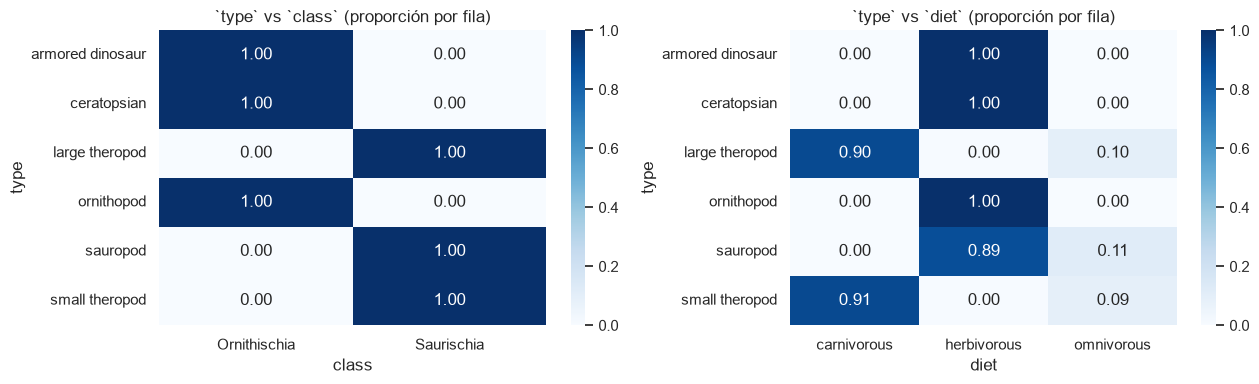

In [14]:
def cramers_v(a, b):
    """Asociación entre dos categóricas (0 = nada, 1 = una determina a la otra)."""
    tabla = pd.crosstab(a, b)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k))

categoricas = ["class", "diet", "family", "region", "name"]
v = pd.Series({c: cramers_v(df[c], df[TARGET]) for c in categoricas}).sort_values(ascending=False)
print("Cramér's V frente a `type`:\n", v.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
for eje, col in zip(ejes, ["class", "diet"]):
    sns.heatmap(pd.crosstab(df[TARGET], df[col], normalize="index"),
                annot=True, fmt=".2f", cmap="Blues", ax=eje)
    eje.set_title(f"`type` vs `{col}` (proporción por fila)")
plt.tight_layout()
plt.show()

## 5. Variables numéricas por clase

type               armored dinosaur  ceratopsian  large theropod  ornithopod  \
length_m   mean                6.28         5.69            8.86        7.14   
           median              6.50         6.00            9.00        7.00   
           std                 2.03         3.00            3.46        3.38   
edad_media mean              117.29        81.62          103.19       96.28   
           median            117.24        77.05           77.85       77.05   
           std                36.76        19.37           37.36       31.39   
duracion   mean               10.67        11.61            9.69       10.57   
           median             11.50        11.50            6.40       11.50   
           std                 5.37         8.73            6.32        5.88   
lat        mean               38.84        45.69           38.34       42.70   
           median             43.30        45.39           43.12       45.57   
           std                16.87     

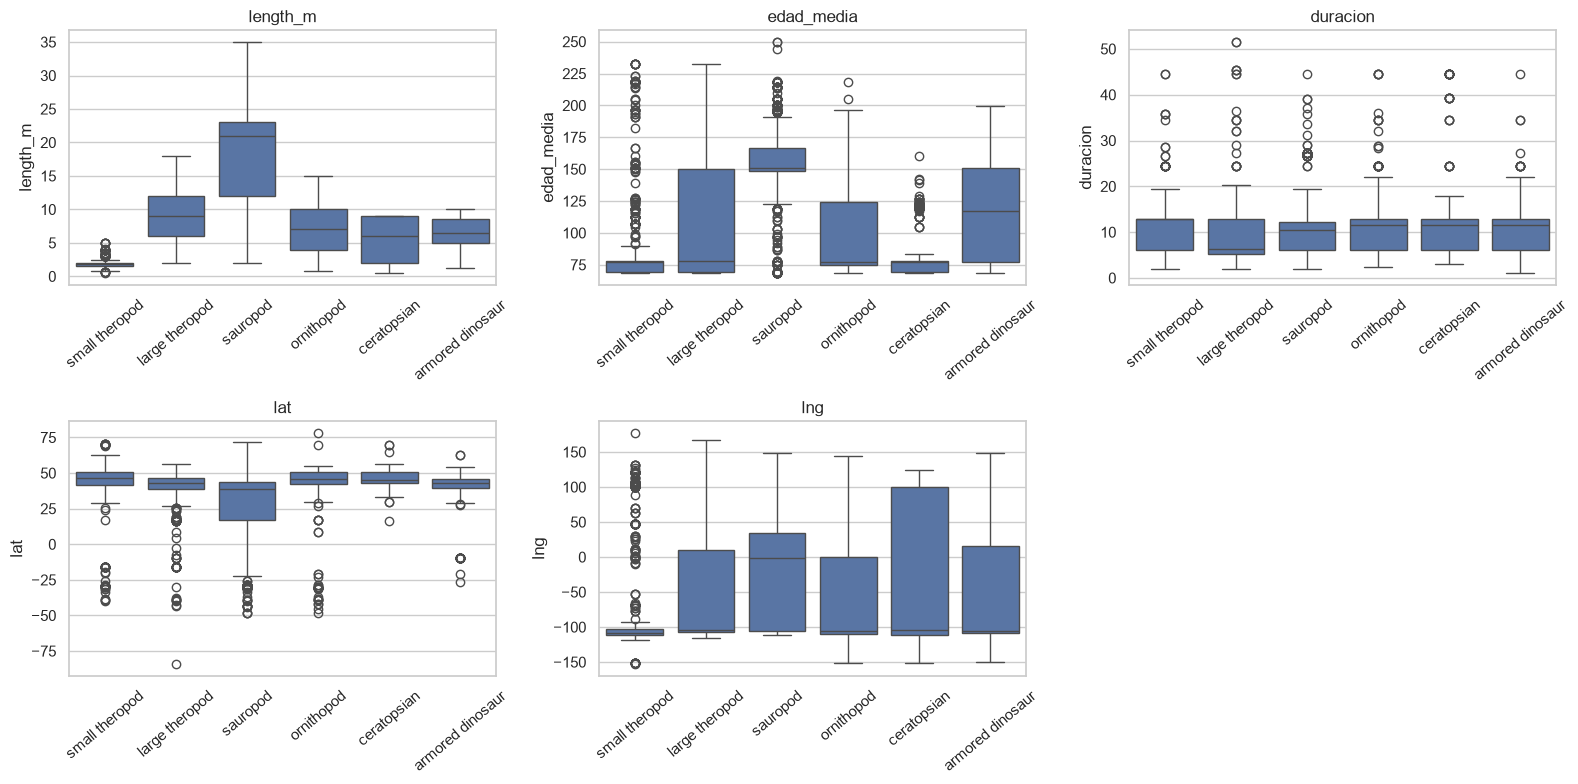

In [15]:
df["edad_media"] = (df["max_ma"] + df["min_ma"]) / 2
df["duracion"] = df["max_ma"] - df["min_ma"]
numericas = ["length_m", "edad_media", "duracion", "lat", "lng"]

print(df.groupby(TARGET)[numericas].agg(["mean", "median", "std"]).round(2).T)

fig, ejes = plt.subplots(2, 3, figsize=(16, 8))
for eje, col in zip(ejes.ravel(), numericas):
    sns.boxplot(data=df, x=TARGET, y=col, ax=eje)
    eje.set_title(col)
    eje.tick_params(axis="x", rotation=40)
    eje.set_xlabel("")
ejes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [16]:
# Fuerza de la asociación: Kruskal-Wallis + tamaño del efecto (eta² basado en H).
# Con 2793 filas casi cualquier p-valor sale minúsculo, así que fíjate en el efecto.
n, k = len(df), df[TARGET].nunique()
filas = []
for col in numericas:
    H, p = kruskal(*[g[col].to_numpy() for _, g in df.groupby(TARGET)])
    filas.append({"variable": col, "H": round(H, 1), "p": p, "eta2": round((H - k + 1) / (n - k), 3)})
print(pd.DataFrame(filas).sort_values("eta2", ascending=False).to_string(index=False))

# ¿Los dos tipos de terópodo se separan solo por tamaño?
print("\nRango de length_m por clase:")
print(df.groupby(TARGET)["length_m"].agg(["min", "max"]))

  variable      H             p  eta2
  length_m 2094.7  0.000000e+00 0.587
edad_media  858.5 2.593885e-183 0.240
       lat  473.8 3.574047e-100 0.132
       lng  271.5  1.335091e-56 0.075
  duracion   78.9  1.403400e-15 0.021

Rango de length_m por clase:
                   min   max
type                        
armored dinosaur  1.20  10.0
ceratopsian       0.50   9.0
large theropod    2.00  18.0
ornithopod        0.80  15.0
sauropod          2.00  35.0
small theropod    0.45   5.0


## 6. Mapa: ¿hay patrón geográfico?

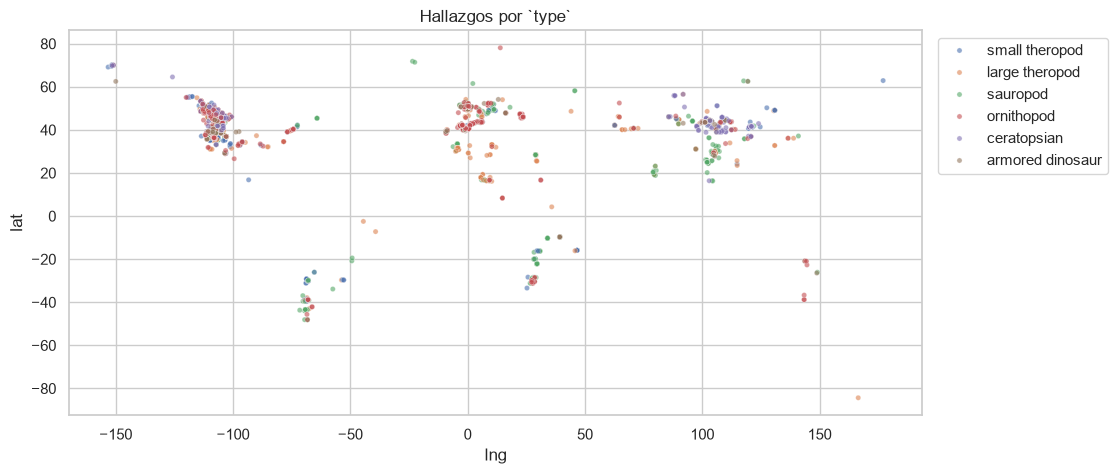

In [17]:
plt.figure(figsize=(11, 5))
sns.scatterplot(data=df, x="lng", y="lat", hue=TARGET, s=14, alpha=0.6)
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Hallazgos por `type`")
plt.show()

## 7. Prueba rápida de viabilidad (no es el modelo final)
Comparamos contra un baseline y mostramos por qué importa validar **por taxón**:
si un mismo `name` cae en train y test, la métrica sale inflada.

In [19]:
y, grupos = df[TARGET], df["name"]
sin_fuga = df[["length_m", "edad_media", "duracion", "lat", "lng"]]
con_fuga = pd.concat([sin_fuga, pd.get_dummies(df[["diet", "class"]], dtype=int)], axis=1)

cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
cv_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

arbol = DecisionTreeClassifier(max_depth=5, random_state=42)
bosque = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
base = DummyClassifier(strategy="most_frequent")

experimentos = [
    ("Baseline (clase mayoritaria)", base, sin_fuga[["length_m"]], cv_grupos),
    ("Árbol, solo length_m", arbol, sin_fuga[["length_m"]], cv_grupos),
    ("Bosque, sin fugas (validación por taxón)", bosque, sin_fuga, cv_grupos),
    ("Bosque, sin fugas (validación AL AZAR)", bosque, sin_fuga, cv_azar),
    ("Bosque, CON diet y class (fuga)", bosque, con_fuga, cv_grupos),
]
resultados = []
for nombre, modelo, X, cv in experimentos:
    puntos = cross_val_score(modelo, X, y, cv=cv,
                         groups=grupos if cv is cv_grupos else None,
                         scoring="f1_macro")
    resultados.append({"experimento": nombre, "F1 macro": round(puntos.mean(), 3), "desv.": round(puntos.std(), 3)})
print(pd.DataFrame(resultados).to_string(index=False))

                             experimento  F1 macro  desv.
            Baseline (clase mayoritaria)     0.061  0.002
                    Árbol, solo length_m     0.380  0.040
Bosque, sin fugas (validación por taxón)     0.432  0.069
  Bosque, sin fugas (validación AL AZAR)     0.890  0.008
         Bosque, CON diet y class (fuga)     0.696  0.057


## 8. Conclusiones
- Balance de clases: Ratio mayor/menor = 2,63. Indica un desbalanceo moderado
- Fugas detectadas y columnas que se excluyen del modelo: class (V = 0,999) y family (0,980) casi determinan type. name (1,0) y occurrence_no son identificadores. diet (0,696) también se excluye: al añadirla junto con class, el F1 macro sube de 0,432 a 0,696
- Variables con señal real y su tamaño de efecto: length_m tiene el mayor efecto (eta² = 0,587), seguida de edad_media, lat y lng. duracion es despreciable (0,021)
- Granularidad y estrategia de validación: hay 288 taxones en 3568 filas. Con validación al azar el F1 macro es 0,889, y agrupando por taxón baja a 0,432. Hay que usar StratifiedGroupKFold por name
- Decisión final (mantener `type` / cambiar de objetivo) y por qué: el baseline está en 0,061, así que el bosque sin fugas lo multiplica por 7. Aun así, un F1 de ≈ 0,43 es moderado